**Assignment 2 — Task 3: Model Evaluation & Discussion**

---

**1. Setup — Load Config, Test Data & Trained Models**

In [1]:
# ── Imports ───────────────────────────────────────────────────────────────────
import os, json, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                              precision_recall_fscore_support, f1_score, roc_curve, auc)
from sklearn.preprocessing import label_binarize
from scipy.stats import chi2
from PIL import Image

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f"TensorFlow    : {tf.__version__}")
print(f"GPU available : {len(tf.config.list_physical_devices('GPU')) > 0}")

TensorFlow    : 2.10.0
GPU available : True


In [2]:
# ── Load config from A1 Task 2 ────────────────────────────────────────────────
with open('dataset_config.json') as f:
    cfg = json.load(f)

TEST_DIR   = cfg['TEST_DIR']
IMG_SIZE   = tuple(cfg['IMG_SIZE'])
BATCH_SIZE = cfg['BATCH_SIZE']
N_CLASSES  = cfg['N_CLASSES']
CLASSES    = cfg['CLASSES']

# Test set: rescale only, no augmentation, no shuffling (so predictions line up
# 1:1 with test_gen.classes / test_gen.filepaths for error analysis later)
test_datagen = ImageDataGenerator(rescale=1./255)
test_gen = test_datagen.flow_from_directory(
    TEST_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', seed=SEED, shuffle=False
)
print(f"Test images: {test_gen.samples}")

Found 2407 images belonging to 15 classes.
Test images: 2407


In [3]:
# ── Load the best available trained models (prefers tuned versions from Task 2) ──
def load_first_existing(paths):
    for p in paths:
        if os.path.exists(p):
            print(f"Loaded: {p}")
            return tf.keras.models.load_model(p)
    raise FileNotFoundError(
        f"None of the expected model files were found in the working directory: {paths}\n"
        f"Make sure A2_Task1 (and ideally A2_Task2) have been run and their .keras "
        f"outputs are available in this Kaggle session (Add Data from a previous version, "
        f"or run all notebooks in the same session)."
    )

cnn_model = load_first_existing(
    ['best_tuned_cnn.keras', 'model_tuned_cnn.keras', 'model_custom_cnn.keras']
)
resnet_model = load_first_existing(
    ['best_tuned_resnet.keras', 'model_tuned_resnet.keras', 'model_resnet_transfer.keras']
)

Loaded: best_tuned_cnn.keras
Your GPUs may run slowly with dtype policy mixed_float16 because they do not have compute capability of at least 7.0. Your GPUs:
  DML, no compute capability (probably not an Nvidia GPU) (x2)
See https://developer.nvidia.com/cuda-gpus for a list of GPUs and their compute capabilities.
If you will use compatible GPU(s) not attached to this host, e.g. by running a multi-worker model, you can ignore this warning. This message will only be logged once
Loaded: best_tuned_resnet.keras


---
**2. Comprehensive Evaluation Metrics**

In [4]:
# ── Run both models over the full test set once, reuse predictions everywhere ──
def evaluate_model(model, gen, name):
    gen.reset()
    probs = model.predict(gen, verbose=1)
    y_pred = np.argmax(probs, axis=1)
    y_true = gen.classes
    acc = accuracy_score(y_true, y_pred)
    top3 = np.mean([y_true[i] in np.argsort(probs[i])[-3:] for i in range(len(y_true))])
    m_prec, m_rec, m_f1, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
    w_prec, w_rec, w_f1, _ = precision_recall_fscore_support(y_true, y_pred, average='weighted', zero_division=0)
    metrics = {
        'Model': name, 'Accuracy': acc, 'Top-3 Accuracy': top3,
        'Macro Precision': m_prec, 'Macro Recall': m_rec, 'Macro F1': m_f1,
        'Weighted F1': w_f1,
    }
    return metrics, y_pred, probs, y_true

cnn_metrics, cnn_pred, cnn_probs, y_true_test = evaluate_model(cnn_model, test_gen, 'Custom CNN')
resnet_metrics, resnet_pred, resnet_probs, _   = evaluate_model(resnet_model, test_gen, 'ResNet50 TL')

eval_summary = pd.DataFrame([cnn_metrics, resnet_metrics])
print("\n" + "=" * 70)
print("TEST SET — COMPREHENSIVE EVALUATION SUMMARY")
print("=" * 70)
print(eval_summary.to_string(index=False, float_format=lambda x: f'{x:.4f}'))

76/76 [==============================] - 19s 232ms/step

TEST SET — COMPREHENSIVE EVALUATION SUMMARY
      Model  Accuracy  Top-3 Accuracy  Macro Precision  Macro Recall  Macro F1  Weighted F1
 Custom CNN    0.1994          0.4516           0.4300        0.2440    0.1937       0.1968
ResNet50 TL    0.4483          0.6739           0.4447        0.4917    0.4284       0.4679


In [5]:
# ── Full per-class classification reports ─────────────────────────────────────
print("Classification Report — Custom CNN")
print(classification_report(y_true_test, cnn_pred, target_names=CLASSES, zero_division=0))

print("\nClassification Report — ResNet50 Transfer Learning")
print(classification_report(y_true_test, resnet_pred, target_names=CLASSES, zero_division=0))

Classification Report — Custom CNN
              precision    recall  f1-score   support

      Beetle       0.11      0.54      0.18       100
   Butterfly       0.28      0.67      0.39       100
         Cat       1.00      0.02      0.03       394
         Cow       0.88      0.08      0.15       177
         Dog       0.25      0.15      0.19        88
    Elephant       0.87      0.29      0.44       306
     Gorilla       0.37      0.23      0.29        30
       Hippo       0.26      0.14      0.18        57
      Lizard       0.09      0.81      0.16       100
      Monkey       0.33      0.01      0.02       184
       Mouse       0.03      0.08      0.05       100
       Panda       0.86      0.35      0.50       237
      Spider       0.12      0.18      0.14       100
       Tiger       0.00      0.00      0.00       164
       Zebra       1.00      0.10      0.19       270

    accuracy                           0.20      2407
   macro avg       0.43      0.24      0.19  

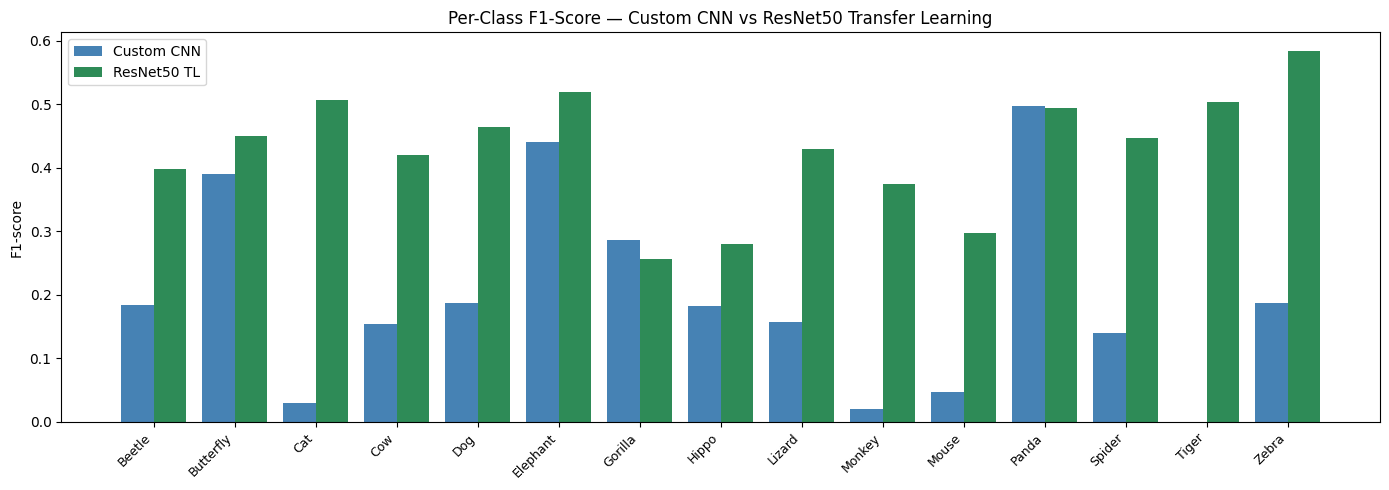

    Class  Custom CNN F1  ResNet50 TL F1  Gap (ResNet - CNN)
  Gorilla          0.286           0.257              -0.029
    Panda          0.497           0.495              -0.002
Butterfly          0.391           0.451               0.060
 Elephant          0.440           0.520               0.080
    Hippo          0.182           0.281               0.099
   Beetle          0.184           0.398               0.214
    Mouse          0.047           0.297               0.250
      Cow          0.155           0.420               0.265
   Lizard          0.158           0.429               0.271
      Dog          0.187           0.464               0.277
   Spider          0.141           0.446               0.306
   Monkey          0.021           0.375               0.354
    Zebra          0.188           0.584               0.396
      Cat          0.030           0.507               0.477
    Tiger          0.000           0.503               0.503


In [6]:
# ── Per-class F1 comparison — where does each model actually win/lose? ───────
cnn_f1_per_class    = f1_score(y_true_test, cnn_pred, average=None, zero_division=0)
resnet_f1_per_class = f1_score(y_true_test, resnet_pred, average=None, zero_division=0)

x = np.arange(N_CLASSES)
fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(x - 0.2, cnn_f1_per_class,    0.4, label='Custom CNN',  color='steelblue')
ax.bar(x + 0.2, resnet_f1_per_class, 0.4, label='ResNet50 TL', color='seagreen')
ax.set_xticks(x); ax.set_xticklabels(CLASSES, rotation=45, ha='right', fontsize=9)
ax.set_ylabel('F1-score')
ax.set_title('Per-Class F1-Score — Custom CNN vs ResNet50 Transfer Learning')
ax.legend()
plt.tight_layout()
plt.savefig('per_class_f1_comparison.png', dpi=150)
plt.show()

f1_gap = pd.DataFrame({
    'Class': CLASSES, 'Custom CNN F1': cnn_f1_per_class, 'ResNet50 TL F1': resnet_f1_per_class,
})
f1_gap['Gap (ResNet - CNN)'] = f1_gap['ResNet50 TL F1'] - f1_gap['Custom CNN F1']
print(f1_gap.sort_values('Gap (ResNet - CNN)').to_string(index=False, float_format=lambda x: f'{x:.3f}'))

---
**3. Statistical Significance Testing (McNemar's Test)**

In [7]:
# ── McNemar's test — is the accuracy difference between the two models ───────
#    actually statistically significant, or could it be noise? Appropriate here
#    because both models are evaluated on the *same* paired test samples.
def mcnemar_test(y_true, pred_a, pred_b):
    correct_a = (pred_a == y_true)
    correct_b = (pred_b == y_true)
    b = int(np.sum(correct_a & ~correct_b))   # A correct, B wrong
    c = int(np.sum(~correct_a & correct_b))   # A wrong, B correct
    if b + c == 0:
        return 0.0, 1.0, b, c
    stat = (abs(b - c) - 1) ** 2 / (b + c)     # continuity-corrected
    p_value = 1 - chi2.cdf(stat, df=1)
    return stat, p_value, b, c

stat, p_value, b, c = mcnemar_test(y_true_test, cnn_pred, resnet_pred)
print(f"CNN-only-correct count  (b): {b}")
print(f"ResNet-only-correct count (c): {c}")
print(f"McNemar chi-square statistic : {stat:.4f}")
print(f"p-value                      : {p_value:.6f}")

alpha = 0.05
if p_value < alpha:
    better = 'ResNet50 TL' if c > b else 'Custom CNN'
    print(f"\n=> Statistically significant difference at α={alpha} — {better} is the "
          f"stronger classifier on this test set (not just a lucky split).")
else:
    print(f"\n=> No statistically significant difference detected at α={alpha} — the "
          f"observed accuracy gap could plausibly be due to sampling noise.")

CNN-only-correct count  (b): 198
ResNet-only-correct count (c): 797
McNemar chi-square statistic : 359.4010
p-value                      : 0.000000

=> Statistically significant difference at α=0.05 — ResNet50 TL is the stronger classifier on this test set (not just a lucky split).


---
**4. Error Analysis — Misclassified Samples**

ResNet50 TL: 1328 misclassified out of 2407 test images (55.2%)


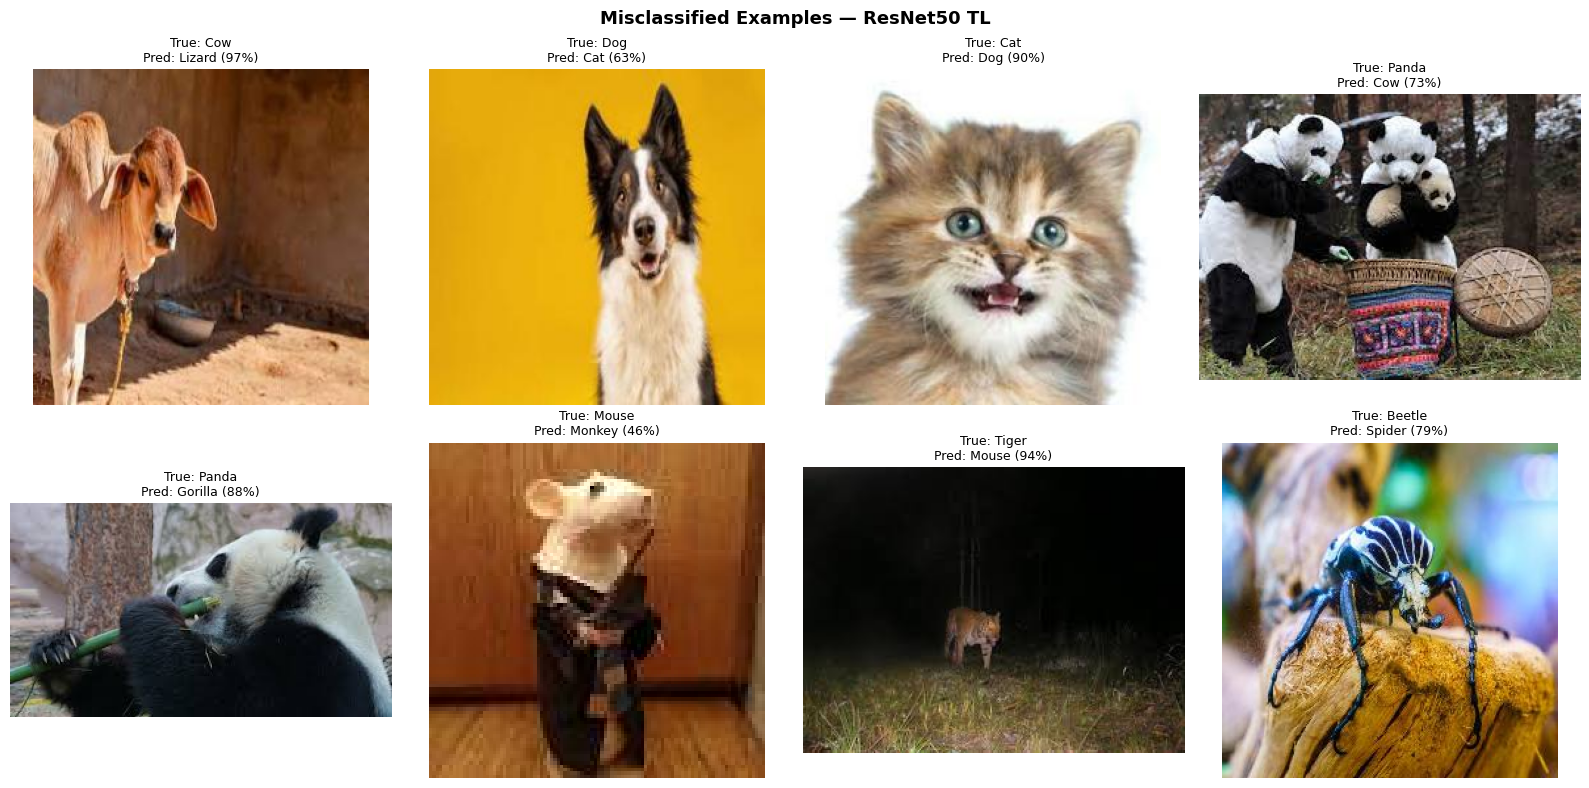

In [8]:
# ── Identify and visualise misclassified examples for the stronger model ─────
best_name, best_pred, best_probs = (
    ('ResNet50 TL', resnet_pred, resnet_probs) if resnet_metrics['Accuracy'] >= cnn_metrics['Accuracy']
    else ('Custom CNN', cnn_pred, cnn_probs)
)

mis_idx = np.where(best_pred != y_true_test)[0]
print(f"{best_name}: {len(mis_idx)} misclassified out of {len(y_true_test)} test images "
      f"({len(mis_idx) / len(y_true_test) * 100:.1f}%)")

n_show = min(8, len(mis_idx))
if n_show > 0:
    sample_mis = np.random.choice(mis_idx, size=n_show, replace=False)
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    for ax, idx in zip(axes.flatten(), sample_mis):
        img = Image.open(test_gen.filepaths[idx]).convert('RGB')
        confidence = best_probs[idx][best_pred[idx]]
        ax.imshow(img)
        ax.set_title(f"True: {CLASSES[y_true_test[idx]]}\nPred: {CLASSES[best_pred[idx]]} ({confidence:.0%})",
                     fontsize=9)
        ax.axis('off')
    for ax in axes.flatten()[n_show:]:
        ax.axis('off')
    plt.suptitle(f'Misclassified Examples — {best_name}', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.savefig('misclassified_examples.png', dpi=150)
    plt.show()
else:
    print("No misclassifications to display.")

In [9]:
# ── Most-confused class pairs (largest off-diagonal confusion-matrix entries) ─
cm = confusion_matrix(y_true_test, best_pred)
cm_off_diag = cm.copy()
np.fill_diagonal(cm_off_diag, 0)

confused_pairs = []
for i in range(N_CLASSES):
    for j in range(N_CLASSES):
        if cm_off_diag[i, j] > 0:
            confused_pairs.append((CLASSES[i], CLASSES[j], int(cm_off_diag[i, j])))
confused_pairs.sort(key=lambda t: -t[2])

print(f"Top confused class pairs (true → predicted) — {best_name}:")
for true_c, pred_c, count in confused_pairs[:10]:
    print(f"  {true_c:12s} → {pred_c:12s} : {count} times")

Top confused class pairs (true → predicted) — ResNet50 TL:
  Cat          → Mouse        : 66 times
  Cat          → Dog          : 46 times
  Elephant     → Cow          : 45 times
  Panda        → Monkey       : 34 times
  Elephant     → Hippo        : 33 times
  Elephant     → Gorilla      : 30 times
  Cat          → Gorilla      : 26 times
  Zebra        → Tiger        : 25 times
  Zebra        → Lizard       : 23 times
  Monkey       → Gorilla      : 22 times


---
**5. Model Interpretability — Grad-CAM**

In [10]:
# ── Grad-CAM: visualise *where* each model looks when making a prediction ────

CNN_LAST_CONV = next(l.name for l in reversed(cnn_model.layers)
                      if isinstance(l, tf.keras.layers.Conv2D))
print(f"Custom CNN — Grad-CAM target layer: {CNN_LAST_CONV}")

def gradcam_flat(model, img_array, last_conv_name, pred_index=None):
    grad_model = tf.keras.Model(model.inputs, [model.get_layer(last_conv_name).output, model.output])
    with tf.GradientTape() as tape:
        conv_out, preds = grad_model(img_array)
        if pred_index is None:
            pred_index = int(tf.argmax(preds[0]))
        class_score = preds[:, pred_index]
    grads = tape.gradient(class_score, conv_out)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_out = conv_out[0]
    heatmap = conv_out @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy(), int(pred_index)


def build_resnet_gradcam_model(resnet_model, img_size):
    """Builds a parallel graph (shared weights, not retrained) that exposes the
    ResNet50 sub-model's own final conv activation map for Grad-CAM."""
    nested = next(l for l in resnet_model.layers if isinstance(l, tf.keras.Model))
    nested_idx = resnet_model.layers.index(nested)
    head_layers = resnet_model.layers[nested_idx + 1:]

    inp = tf.keras.Input(shape=(*img_size, 3))
    x = tf.keras.applications.resnet50.preprocess_input(inp * 255.0)
    conv_features = nested(x, training=False)
    head = conv_features
    for layer in head_layers:
        head = layer(head, training=False)
    return tf.keras.Model(inp, [conv_features, head])


def gradcam_nested(gradcam_model, img_array, pred_index=None):
    with tf.GradientTape() as tape:
        conv_out, preds = gradcam_model(img_array)
        if pred_index is None:
            pred_index = int(tf.argmax(preds[0]))
        class_score = preds[:, pred_index]
    grads = tape.gradient(class_score, conv_out)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_out = conv_out[0]
    heatmap = conv_out @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy(), int(pred_index)


def overlay_heatmap(img_array_0to1, heatmap, alpha=0.4):
    heatmap_resized = np.array(Image.fromarray(np.uint8(255 * heatmap)).resize(
        (img_array_0to1.shape[1], img_array_0to1.shape[0])))
    cmap = plt.get_cmap('jet')
    heatmap_colored = cmap(heatmap_resized / 255.0)[..., :3]
    overlaid = heatmap_colored * alpha + img_array_0to1 * (1 - alpha)
    return np.clip(overlaid, 0, 1)

resnet_gradcam_model = build_resnet_gradcam_model(resnet_model, IMG_SIZE)
print("Grad-CAM helper models ready.")

Custom CNN — Grad-CAM target layer: conv2d_15
Grad-CAM helper models ready.


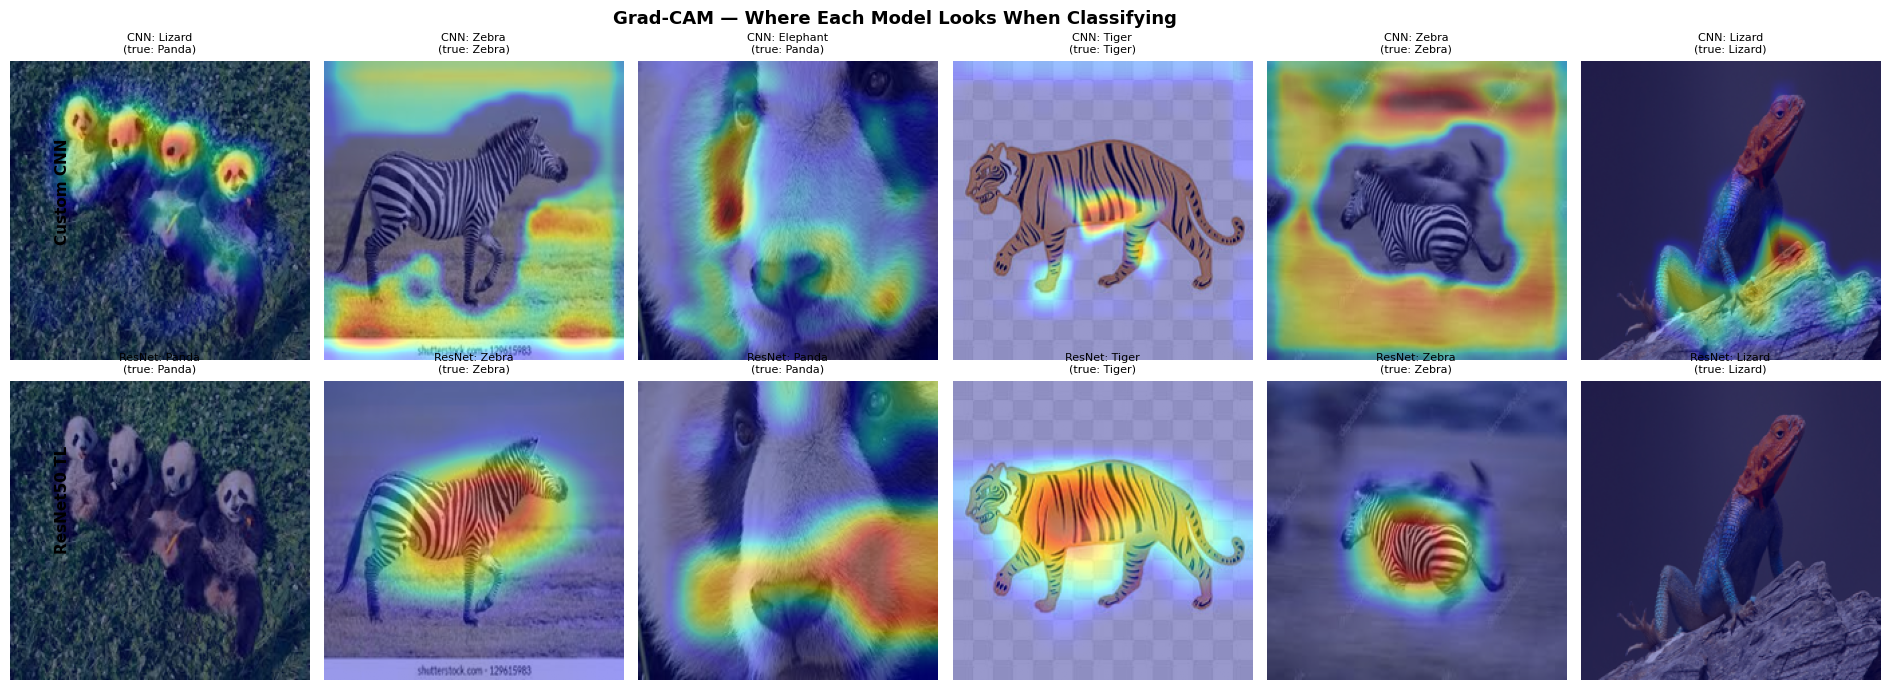

In [11]:
# ── Compare where each model looks on the same set of sample test images ─────
try:
    sample_idx = np.random.choice(len(test_gen.filepaths), 6, replace=False)
    fig, axes = plt.subplots(2, 6, figsize=(20, 7))
    for col, idx in enumerate(sample_idx):
        img_path = test_gen.filepaths[idx]
        true_label = CLASSES[y_true_test[idx]]
        img = np.array(Image.open(img_path).convert('RGB').resize(IMG_SIZE)) / 255.0
        img_batch = np.expand_dims(img, 0).astype(np.float32)

        heatmap_cnn, pred_cnn = gradcam_flat(cnn_model, img_batch, CNN_LAST_CONV)
        heatmap_res, pred_res = gradcam_nested(resnet_gradcam_model, img_batch)

        axes[0][col].imshow(overlay_heatmap(img, heatmap_cnn))
        axes[0][col].set_title(f"CNN: {CLASSES[pred_cnn]}\n(true: {true_label})", fontsize=8)
        axes[0][col].axis('off')

        axes[1][col].imshow(overlay_heatmap(img, heatmap_res))
        axes[1][col].set_title(f"ResNet: {CLASSES[pred_res]}\n(true: {true_label})", fontsize=8)
        axes[1][col].axis('off')

    fig.text(0.08, 0.72, 'Custom CNN',  fontsize=11, fontweight='bold', rotation=90, va='center')
    fig.text(0.08, 0.28, 'ResNet50 TL', fontsize=11, fontweight='bold', rotation=90, va='center')
    plt.suptitle('Grad-CAM — Where Each Model Looks When Classifying', fontsize=13, fontweight='bold')
    plt.tight_layout(rect=[0.05, 0, 1, 1])
    plt.savefig('gradcam_comparison.png', dpi=150)
    plt.show()
except Exception as e:
    print(f"Grad-CAM visualisation skipped due to an environment/model-structure issue: {e}")
    print("This does not affect the metrics/statistical results computed above.")

---
**6. ROC Curves (Multi-Class, One-vs-Rest)**

Custom CNN — Macro-average ROC-AUC: 0.7720
ResNet50 TL — Macro-average ROC-AUC: 0.8288


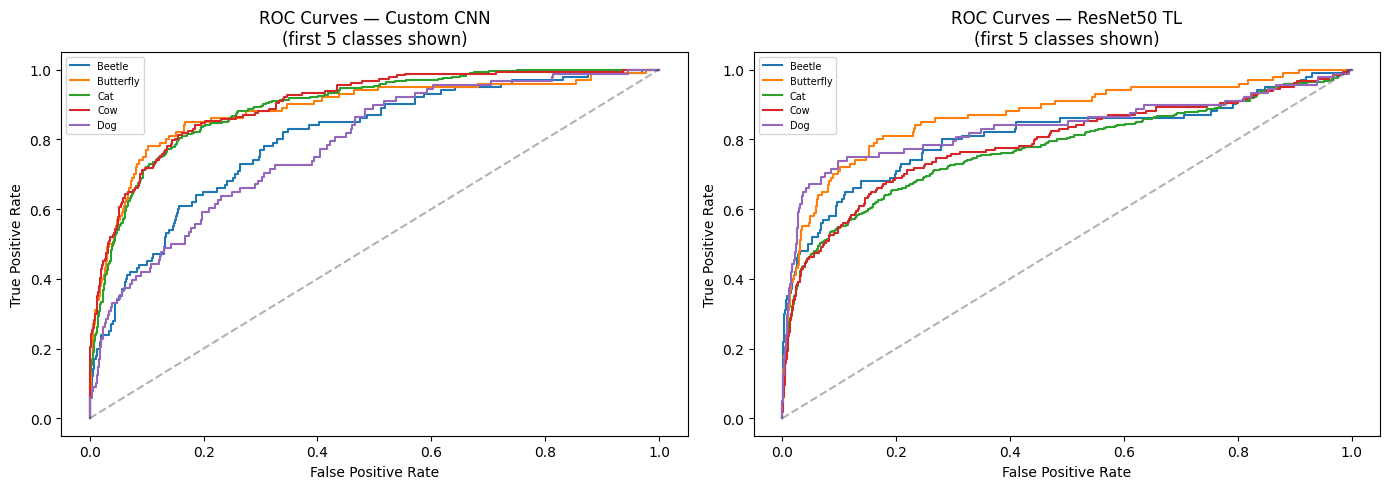

In [12]:
# ── Macro-average ROC-AUC (one-vs-rest) for both models ───────────────────────
y_true_bin = label_binarize(y_true_test, classes=range(N_CLASSES))

def macro_roc_auc(probs, name):
    fpr, tpr, roc_auc = {}, {}, {}
    for i in range(N_CLASSES):
        fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], probs[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])
    macro_auc = float(np.mean(list(roc_auc.values())))
    print(f"{name} — Macro-average ROC-AUC: {macro_auc:.4f}")
    return macro_auc, fpr, tpr, roc_auc

cnn_macro_auc, cnn_fpr, cnn_tpr, _          = macro_roc_auc(cnn_probs, 'Custom CNN')
resnet_macro_auc, resnet_fpr, resnet_tpr, _ = macro_roc_auc(resnet_probs, 'ResNet50 TL')

show_classes = list(range(min(5, N_CLASSES)))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for i in show_classes:
    axes[0].plot(cnn_fpr[i], cnn_tpr[i], label=CLASSES[i])
    axes[1].plot(resnet_fpr[i], resnet_tpr[i], label=CLASSES[i])
for ax, title in zip(axes, ['Custom CNN', 'ResNet50 TL']):
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.3)
    ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
    ax.set_title(f'ROC Curves — {title}\n(first {len(show_classes)} classes shown)')
    ax.legend(fontsize=7)
plt.tight_layout()
plt.savefig('roc_curves_comparison.png', dpi=150)
plt.show()

---
**7. Save Results for Task 4**

In [13]:
# ── Persist everything Task 4 needs so it can run independently ──────────────
eval_summary_full = eval_summary.copy()
eval_summary_full.loc[eval_summary_full['Model'] == 'Custom CNN',  'Macro ROC-AUC'] = cnn_macro_auc
eval_summary_full.loc[eval_summary_full['Model'] == 'ResNet50 TL', 'Macro ROC-AUC'] = resnet_macro_auc
eval_summary_full.to_csv('task3_evaluation_summary.csv', index=False)

with open('task3_predictions.pkl', 'wb') as f:
    pickle.dump({
        'y_true'        : y_true_test,
        'cnn_pred'      : cnn_pred,      'resnet_pred'  : resnet_pred,
        'cnn_probs'     : cnn_probs,     'resnet_probs' : resnet_probs,
        'cnn_macro_auc' : cnn_macro_auc, 'resnet_macro_auc': resnet_macro_auc,
        'test_filepaths': test_gen.filepaths,
    }, f)

print("✓ Saved task3_evaluation_summary.csv and task3_predictions.pkl for use in Task 4.")
print(eval_summary_full.to_string(index=False, float_format=lambda x: f'{x:.4f}'))

✓ Saved task3_evaluation_summary.csv and task3_predictions.pkl for use in Task 4.
      Model  Accuracy  Top-3 Accuracy  Macro Precision  Macro Recall  Macro F1  Weighted F1  Macro ROC-AUC
 Custom CNN    0.1994          0.4516           0.4300        0.2440    0.1937       0.1968         0.7720
ResNet50 TL    0.4483          0.6739           0.4447        0.4917    0.4284       0.4679         0.8288
